In [1]:
%cd C:\Mestrado\Graph_Pruning\prodigy

C:\Mestrado\Graph_Pruning\prodigy


c:\Mestrado\Graph_Pruning\.venv_prodigy\lib\site-packages\IPython\core\magics\osm.py:417: UserWarning: This is now an optional IPython functionality, setting dhist requires you to install the `pickleshare` library.
  self.shell.db['dhist'] = compress_dhist(dhist)[-100:]


In [2]:

from pathlib import Path
import sys
import gc

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F

# Caminhos do projeto
PROJECT_ROOT = Path(r"C:\Mestrado\Graph_Pruning")
REPO_ROOT = PROJECT_ROOT / "prodigy"
DATA_ROOT = REPO_ROOT / "data" / "datasets"

CHECKPOINT_DIR = (
    REPO_ROOT / "state" / "Wiki_PT_PRODIGY_02_10_2026_16_26_51"
)

# Permitir imports do PRODIGY
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

# Dispositivo
device = torch.device(
    "cuda:0" if torch.cuda.is_available() else "cpu"
)

print("Repositório:", REPO_ROOT)
print("Dataset:", DATA_ROOT / "FB15K-237")
print("Checkpoint:", CHECKPOINT_DIR)
print("Dispositivo:", device)
print("CUDA disponível:", torch.cuda.is_available())


Repositório: C:\Mestrado\Graph_Pruning\prodigy
Dataset: C:\Mestrado\Graph_Pruning\prodigy\data\datasets\FB15K-237
Checkpoint: C:\Mestrado\Graph_Pruning\prodigy\state\Wiki_PT_PRODIGY_02_10_2026_16_26_51
Dispositivo: cuda:0
CUDA disponível: True


In [3]:
CONFIG = {
    "dataset": "FB15K-237",
    "layers": "S2,UX,M2",
    "task_name": "cls_nm",
    "n_way": 3,
    "n_shot": 3,
    "n_query": 3,
    "batch_size": 1,
    "dataset_len_cap": 510,
    "val_len_cap": 100,
    "test_len_cap": 500,
    "train_cap": 10,
    "num_workers": 0,
    "emb_dim": 256,
    "input_dim": 770,
}

print(pd.Series(CONFIG, name="Valor"))

dataset            FB15K-237
layers              S2,UX,M2
task_name             cls_nm
n_way                      3
n_shot                     3
n_query                    3
batch_size                 1
dataset_len_cap          510
val_len_cap              100
test_len_cap             500
train_cap                 10
num_workers                0
emb_dim                  256
input_dim                770
Name: Valor, dtype: object


In [4]:
import torch

DEVICE = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

print("Dispositivo:", DEVICE)

Dispositivo: cuda:0


In [5]:
from data.data_loader_wrapper import get_dataset_wrap

datasets = get_dataset_wrap(
    root=str(DATA_ROOT),
    dataset=CONFIG["dataset"],
    n_hop=1,
    bert="sentence-transformers/all-mpnet-base-v2",
    bert_device=str(DEVICE),
    node_graph=False,
)

print("Dataset carregado:", type(datasets).__name__)
print("Dataset:", CONFIG["dataset"])

Use cache from:  C:\Mestrado\Graph_Pruning\prodigy\data\datasets\FB15K-237\relation2id.json
Use cache from:  C:\Mestrado\Graph_Pruning\prodigy\data\datasets\FB15K-237\entity2id.json


100%|██████████| 200/200 [00:00<00:00, 2485.20it/s]


Use cache from:  C:\Mestrado\Graph_Pruning\prodigy\data\datasets\FB15K-237\graph.pt
Use cache from:  C:\Mestrado\Graph_Pruning\prodigy\data\datasets\FB15K-237\graph.pt
MODEL NAME:  sentence-transformers/all-mpnet-base-v2
Loading text features from  C:\Mestrado\Graph_Pruning\prodigy\data\datasets\FB15K-237\preproc_text_feats\text_feats_sentence-transformers_all-mpnet-base-v2_.pkl
Loading adjacent matrix for neighbor sampling from C:\Mestrado\Graph_Pruning\prodigy\data\datasets\FB15K-237\FB15K-237_adj.pt
Loaded adjacent matrix for neighbor sampling from C:\Mestrado\Graph_Pruning\prodigy\data\datasets\FB15K-237\FB15K-237_adj.pt
Dataset carregado: KGSubgraphDataset
Dataset: FB15K-237


In [6]:
from data.kg import get_kg_dataloader

dataset_name = CONFIG["dataset"]

dataset_root = str(DATA_ROOT / dataset_name)

loader_kwargs = {
    "batch_size": CONFIG["batch_size"],
    "n_way": CONFIG["n_way"],
    "n_shot": CONFIG["n_shot"],
    "n_query": CONFIG["n_query"],
    "root": dataset_root,
    "num_workers": CONFIG["num_workers"],
    "aug": None,
    "aug_test": None,
    "train_cap": CONFIG["train_cap"],
    "linear_probe": False,
    "split_labels": True,
    "csr_split": False,
}

val_loader = get_kg_dataloader(
    datasets,
    task_name=CONFIG["task_name"],
    split="val",
    node_split="",
    batch_count=CONFIG["val_len_cap"],
    **loader_kwargs,
)

test_loader = get_kg_dataloader(
    datasets,
    task_name=CONFIG["task_name"],
    split="test",
    node_split="",
    batch_count=CONFIG["test_len_cap"],
    **loader_kwargs,
)

print("Lotes de validação:", len(val_loader))
print("Lotes de teste:", len(test_loader))


200
TEST_LABELS 120
VAL_LABELS 40
TRAIN_LABELS 40
200
TEST_LABELS 120
VAL_LABELS 40
TRAIN_LABELS 40
Lotes de validação: 100
Lotes de teste: 500


In [7]:
# Materializar os episódios uma única vez.
# Todos os modelos serão avaliados sobre esta mesma lista.

cached_batches = list(test_loader)

print("Episódios armazenados:", len(cached_batches))
print("Elementos por episódio:", len(cached_batches[0]))

assert len(cached_batches) == CONFIG["test_len_cap"]
assert len(cached_batches[0]) == 9

Episódios armazenados: 500
Elementos por episódio: 9


In [8]:
import sys
from experiments.params import get_params

argv_original = sys.argv.copy()

try:
    sys.argv = [
        "notebook",
        "-root", str(DATA_ROOT),
        "-dataset", "FB15K-237",
        "-layers", "S2,UX,M2",
        "-task", "cls_nm",
        "-way", "3",
        "-shot", "3",
        "-qry", "3",
        "-bs", "1",
        "-ds_cap", "510",
        "-val_cap", "100",
        "-test_cap", "500",
        "-eval_step", "100",
        "-epochs", "3",
        "-train_cap", "10",
        "-gpu", "0",
        "-workers", "0",
    ]

    params = get_params()

finally:
    sys.argv = argv_original
params["input_dim"] = 770
params["bert_emb_model"] = "sentence-transformers/all-mpnet-base-v2"

print("Dataset:", params["dataset"])
print("Camadas:", params["layers"])
print("Tarefa:", params["task_name"])
print("Dispositivo:", params["device"])
print("Dimensão dos embeddings:", params["emb_dim"])
print("Dimensão de entrada:", params["input_dim"])
print("Dimensão dos embeddings:", params["emb_dim"])
print("Dimensão de entrada:", params["input_dim"])
print("Parâmetros preparados:", len(params))

Dataset: FB15K-237
Camadas: S2,UX,M2
Tarefa: cls_nm
Dispositivo: cuda:0
Dimensão dos embeddings: 256
Dimensão de entrada: 770
Dimensão dos embeddings: 256
Dimensão de entrada: 770
Parâmetros preparados: 80


In [9]:
import torch
from pathlib import Path

from models.general_gnn import SingleLayerGeneralGNN
from experiments.layers import get_module_list

# Reproduzir a configuração original do FB15K-237
bert_dim = 768
params["input_dim"] = bert_dim + 2
params["emb_dim"] = 256

initial_label_mlp = torch.nn.Linear(bert_dim, params["emb_dim"])
text_dropout = torch.nn.Dropout(params["text_features_dropout"])

layer_list = get_module_list(
    module_string=params["layers"],
    emb_dim=params["emb_dim"],
    edge_attr_dim=bert_dim,
    input_dim=params["input_dim"],
    dropout=params["dropout"],
    reset_after_layer=params["reset_after_layer"],
    attention_mask_scheme=params["attention_mask_scheme"],
    has_final_back=params["has_final_back"],
    msg_pos_only=params.get("meta_gnn_pos_only", False),
    batch_norm_metagraph=not params["no_bn_metagraph"],
    batch_norm_encoder=not params["no_bn_encoder"],
    gnn_use_relu=True,
)

model = SingleLayerGeneralGNN(
    layer_list=torch.nn.ModuleList(layer_list),
    initial_label_mlp=initial_label_mlp,
    params=params,
    text_dropout=text_dropout,
).to(DEVICE)

model.eval()

print("Modelo construído:", type(model).__name__)
print("Camadas:", [type(layer).__name__ for layer in model.layer_list])
print("Dispositivo:", next(model.parameters()).device)
print("Parâmetros totais:", sum(p.numel() for p in model.parameters()))


Modelo construído: SingleLayerGeneralGNN
Camadas: ['MultiLayerGNN', 'BgGraphToSupernodePropagatorCat', 'MetaGNN']
Dispositivo: cuda:0
Parâmetros totais: 2894723


In [10]:
# Carregar o checkpoint treinado

checkpoint_path = CHECKPOINT_DIR / "state_dict"

checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=False
)

state_dict = checkpoint["model"]

# Carregar os pesos, exigindo compatibilidade completa
model.load_state_dict(state_dict, strict=True)

# Preparar o modelo para inferência
model = model.to(DEVICE)
model.eval()

print("Checkpoint carregado com sucesso!")
print("Modo de avaliação:", not model.training)
print("Dispositivo:", next(model.parameters()).device)
print("Parâmetros totais:", sum(p.numel() for p in model.parameters()))

Checkpoint carregado com sucesso!
Modo de avaliação: True
Dispositivo: cuda:0
Parâmetros totais: 2894723


In [11]:
from sklearn.metrics import accuracy_score, f1_score


def evaluate_model(model, episodes, device, config_name="Modelo"):
    model.eval()

    all_y_true = []
    all_y_pred = []
    episode_results = []

    with torch.inference_mode():
        for episode_idx, episode in enumerate(episodes):

            # O forward altera graph.x.
            # Por isso, usamos uma cópia do grafo original.
            graph = episode[0].clone().to(device)

            # Os nove elementos são passados na ordem original.
            model_inputs = [graph]

            for item in episode[1:]:
                if torch.is_tensor(item):
                    model_inputs.append(item.to(device))
                else:
                    model_inputs.append(item)

            output = model(*model_inputs)

            if not isinstance(output, (tuple, list)) or len(output) < 2:
                raise RuntimeError(
                    f"Saída inesperada do modelo no episódio {episode_idx}."
                )

            y_true = output[0].detach().cpu()
            y_pred = output[1].detach().cpu()

            # As saídas são matrizes de classes:
            # convertemos one-hot/logits para IDs de classe.
            if y_true.ndim > 1:
                y_true = y_true.argmax(dim=-1)

            if y_pred.ndim > 1:
                y_pred = y_pred.argmax(dim=-1)

            y_true = y_true.reshape(-1).numpy()
            y_pred = y_pred.reshape(-1).numpy()

            if len(y_true) != len(y_pred):
                raise ValueError(
                    f"Tamanhos incompatíveis no episódio {episode_idx}: "
                    f"{len(y_true)} rótulos e {len(y_pred)} predições."
                )

            episode_results.append({
                "Episódio": episode_idx,
                "Accuracy": accuracy_score(y_true, y_pred),
                "F1 macro": f1_score(
                    y_true,
                    y_pred,
                    average="macro",
                    zero_division=0,
                ),
            })

            all_y_true.extend(y_true)
            all_y_pred.extend(y_pred)

    episode_df = pd.DataFrame(episode_results)

    summary = {
        "Configuração": config_name,
        "Accuracy média": episode_df["Accuracy"].mean(),
        "Accuracy desvio padrão": episode_df["Accuracy"].std(ddof=0),
        "F1 macro médio": episode_df["F1 macro"].mean(),
        "F1 macro desvio padrão": episode_df["F1 macro"].std(ddof=0),
        "Accuracy global": accuracy_score(all_y_true, all_y_pred),
        "F1 macro global": f1_score(
            all_y_true,
            all_y_pred,
            average="macro",
            zero_division=0,
        ),
        "Batches avaliados": len(episode_df),
        "Exemplos avaliados": len(all_y_true),
    }

    return summary, episode_df

In [12]:
# Garantir que estamos usando o modelo original carregado do checkpoint.
model.eval()

baseline_result, baseline_by_episode = evaluate_model(
    model=model,
    episodes=cached_batches,
    device=DEVICE,
    config_name="Baseline",
)

baseline_df = pd.DataFrame([baseline_result])

display(baseline_df)

,Configuração,Accuracy média,Accuracy desvio padrão,F1 macro médio,F1 macro desvio padrão,Accuracy global,F1 macro global,Batches avaliados,Exemplos avaliados
0,Baseline,0.878889,0.145122,0.867228,0.162714,0.878889,0.878867,500,4500


In [13]:
baseline_df.to_csv(
    "prodigy_baseline_fb15k237.csv",
    index=False,
)

baseline_by_episode.to_csv(
    "prodigy_baseline_por_episodio.csv",
    index=False,
)

print("Resultados do baseline salvos.")

Resultados do baseline salvos.


In [14]:
import inspect

from layer_pruner import PRODIGYBlockInfluencePruner

# Criar o pruner a partir do modelo original, já carregado
pruner = PRODIGYBlockInfluencePruner(model)

Pruner: PRODIGYBlockInfluencePruner

Métodos disponíveis:
  _lowest_bi_layer(block_name: 'str') -> 'int'
  _normalize_bi_dataframe(df_bi: 'pd.DataFrame') -> 'pd.DataFrame'
  _read_layer_input(args, kwargs)
  block_influence(input_hidden_state: 'torch.Tensor', output_hidden_state: 'torch.Tensor', angular: 'bool' = False, eps: 'float' = 1e-08, reduce_mean: 'bool' = True)
  compute_bi(val_loader, device: 'Optional[torch.device | str]' = None, angular: 'bool' = False, max_batches: 'Optional[int]' = None) -> 'pd.DataFrame'
  get_layers_to_remove() -> 'dict[str, list[int]]'
  layer_report() -> 'pd.DataFrame'
  load_bi_from_csv(csv_path: 'str') -> 'pd.DataFrame'
  prune_specific_layers(s2_layers_to_remove: 'Optional[Sequence[int]]' = None, m2_layers_to_remove: 'Optional[Sequence[int]]' = None) -> 'nn.Module'
  prune_tier1() -> 'nn.Module'
  prune_tier2() -> 'nn.Module'
  set_bi_scores(df_bi: 'pd.DataFrame') -> 'pd.DataFrame'
  sparsity_report() -> 'dict[str, int | float]'
  summary() -> 'None

In [15]:
# Garantir que estamos usando o modelo original
model.eval()

# Calcular o Block Influence no conjunto de validação
df_bi = pruner.compute_bi(
    val_loader,
    device=DEVICE,
    angular=False,
    max_batches=CONFIG["val_len_cap"],
)

print("Block Influence calculado.")
print("Número de camadas avaliadas:", len(df_bi))

display(df_bi)

# Salvar o ranking bruto para documentação do experimento
df_bi.to_csv(
    "prodigy_block_influence_fb15k237.csv",
    index=False,
)

print("Arquivo CSV salvo.")

Block Influence calculado.
Número de camadas avaliadas: 4


,Bloco,Layer Index,Camada,Tipo,BI média,Desvio padrão,Lotes válidos,Nós válidos,Lotes ignorados,Métrica,Observação
0,M2,0,M2 - camada 1,MetaGNNLayer,0.437132,0.013049,100,1800,0,BI (1 - cosseno),M2 calculado apenas sobre o prefixo de supernós
1,M2,1,M2 - camada 2,MetaGNNLayer,0.722492,0.028194,100,1800,0,BI (1 - cosseno),M2 calculado apenas sobre o prefixo de supernós
2,S2,0,S2 - camada 1,SAGEConvSelfLoopsV2,1.012816,0.008437,100,170954,0,BI (1 - cosseno),Entrada projetada por lin_x antes da comparação
3,S2,1,S2 - camada 2,SAGEConvSelfLoopsV2,0.171405,0.002626,100,170954,0,BI (1 - cosseno),Entrada/saída da camada com ativação do bloco


Arquivo CSV salvo.


In [16]:
print("Ranking e relatório das camadas:")
display(pruner.layer_report())

print("\nCamadas selecionadas pelo pruner:")
layers_to_remove = pruner.get_layers_to_remove()
print(layers_to_remove)

Ranking e relatório das camadas:


,Bloco,Camadas originais,Camadas restantes,Índices removidos (zero-based)
0,S2,2,2,[]
1,M2,2,2,[]



Camadas selecionadas pelo pruner:
{'S2': [1], 'M2': [0]}


In [18]:
import copy

# Contagem de parâmetros do modelo original
def count_parameters(model):
    return sum(p.numel() for p in model.parameters())

baseline_params = count_parameters(model)

# Criar um pruner independente para o Tier 1
pruner_t1 = PRODIGYBlockInfluencePruner(
    copy.deepcopy(model)
)
pruner_t1.set_bi_scores(df_bi)

model_t1 = pruner_t1.prune_tier1()
model_t1 = model_t1.to(DEVICE)
model_t1.eval()

# Criar outro pruner independente para o Tier 2
pruner_t2 = PRODIGYBlockInfluencePruner(
    copy.deepcopy(model)
)
pruner_t2.set_bi_scores(df_bi)

model_t2 = pruner_t2.prune_tier2()
model_t2 = model_t2.to(DEVICE)
model_t2.eval()

# Verificar as quantidades de parâmetros
results_pruning = []

for name, current_model in [
    ("Baseline", model),
    ("Tier 1", model_t1),
    ("Tier 2", model_t2),
]:
    params_count = count_parameters(current_model)

    reduction = (
        (baseline_params - params_count) / baseline_params * 100
    )

    results_pruning.append({
        "Configuração": name,
        "Parâmetros": params_count,
        "Redução de parâmetros (%)": reduction,
    })

pruning_df = pd.DataFrame(results_pruning)

display(pruning_df)

print("Camadas selecionadas:", layers_to_remove)
print("Tier 1: remove S2", layers_to_remove["S2"])
print("Tier 2: remove S2", layers_to_remove["S2"],
      "e M2", layers_to_remove["M2"])

,Configuração,Parâmetros,Redução de parâmetros (%)
0,Baseline,2894723,0.000000
1,Tier 1,2302851,20.446585
2,Tier 2,2035266,29.690475


Camadas selecionadas: {'S2': [1], 'M2': [0]}
Tier 1: remove S2 [1]
Tier 2: remove S2 [1] e M2 [0]


In [20]:
import copy
import gc
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

# ============================================================
# CONFIGURAÇÃO DO EXPERIMENTO
# ============================================================

N_REPETITIONS = 10
EXPECTED_BATCHES = CONFIG["test_len_cap"]

# Ranking calculado previamente no conjunto de validação.
print("Block Influence utilizado:")
display(df_bi)

print("Camadas selecionadas:")
print(pruner.get_layers_to_remove())

baseline_params = count_parameters(model)

repetition_results = []

# ============================================================
# REPETIÇÕES
# ============================================================

for repetition in range(1, N_REPETITIONS + 1):

    print(f"\n{'=' * 65}")
    print(f"REPETIÇÃO {repetition}/{N_REPETITIONS}")
    print("=" * 65)

    # Obter os episódios desta repetição.
    # A mesma lista será utilizada pelos três modelos.
    evaluation_batches = list(test_loader)

    if len(evaluation_batches) != EXPECTED_BATCHES:
        raise RuntimeError(
            f"Esperados {EXPECTED_BATCHES} batches, "
            f"mas foram obtidos {len(evaluation_batches)}."
        )

    # --------------------------------------------------------
    # BASELINE
    # --------------------------------------------------------

    baseline_result, _ = evaluate_model(
        model=model,
        episodes=evaluation_batches,
        device=DEVICE,
        config_name="Baseline",
    )

    baseline_result["Repetição"] = repetition
    baseline_result["Parâmetros"] = baseline_params
    baseline_result["Redução de parâmetros (%)"] = 0.0

    repetition_results.append(baseline_result)

    # --------------------------------------------------------
    # TIER 1
    # Reconstruir a partir do modelo original
    # --------------------------------------------------------

    pruner_t1_rep = PRODIGYBlockInfluencePruner(
        copy.deepcopy(model)
    )
    pruner_t1_rep.set_bi_scores(df_bi)

    model_t1_rep = pruner_t1_rep.prune_tier1()
    model_t1_rep = model_t1_rep.to(DEVICE)
    model_t1_rep.eval()

    t1_params = count_parameters(model_t1_rep)

    t1_result, _ = evaluate_model(
        model=model_t1_rep,
        episodes=evaluation_batches,
        device=DEVICE,
        config_name="Tier 1",
    )

    t1_result["Repetição"] = repetition
    t1_result["Parâmetros"] = t1_params
    t1_result["Redução de parâmetros (%)"] = (
        100 * (baseline_params - t1_params) / baseline_params
    )

    repetition_results.append(t1_result)

    # --------------------------------------------------------
    # TIER 2
    # Reconstruir novamente a partir do modelo original
    # --------------------------------------------------------

    pruner_t2_rep = PRODIGYBlockInfluencePruner(
        copy.deepcopy(model)
    )
    pruner_t2_rep.set_bi_scores(df_bi)

    model_t2_rep = pruner_t2_rep.prune_tier2()
    model_t2_rep = model_t2_rep.to(DEVICE)
    model_t2_rep.eval()

    t2_params = count_parameters(model_t2_rep)

    t2_result, _ = evaluate_model(
        model=model_t2_rep,
        episodes=evaluation_batches,
        device=DEVICE,
        config_name="Tier 2",
    )

    t2_result["Repetição"] = repetition
    t2_result["Parâmetros"] = t2_params
    t2_result["Redução de parâmetros (%)"] = (
        100 * (baseline_params - t2_params) / baseline_params
    )

    repetition_results.append(t2_result)

    # Resumo da repetição
    print(
        f"Baseline: Acc={baseline_result['Accuracy global']:.4f} | "
        f"F1={baseline_result['F1 macro global']:.4f}"
    )
    print(
        f"Tier 1:   Acc={t1_result['Accuracy global']:.4f} | "
        f"F1={t1_result['F1 macro global']:.4f}"
    )
    print(
        f"Tier 2:   Acc={t2_result['Accuracy global']:.4f} | "
        f"F1={t2_result['F1 macro global']:.4f}"
    )

    # Liberar os modelos temporários antes da próxima repetição.
    del model_t1_rep, model_t2_rep
    del pruner_t1_rep, pruner_t2_rep
    del evaluation_batches

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


# ============================================================
# RESULTADOS POR REPETIÇÃO
# ============================================================

repetitions_df = pd.DataFrame(repetition_results)

display(
    repetitions_df[
        [
            "Repetição",
            "Configuração",
            "Accuracy global",
            "F1 macro global",
            "Parâmetros",
            "Redução de parâmetros (%)",
        ]
    ]
)

repetitions_df.to_csv(
    "prodigy_pruning_repetitions_fb15k237.csv",
    index=False,
)

print("\nResultados de todas as repetições salvos.")

Block Influence utilizado:


,Bloco,Layer Index,Camada,Tipo,BI média,Desvio padrão,Lotes válidos,Nós válidos,Lotes ignorados,Métrica,Observação
0,M2,0,M2 - camada 1,MetaGNNLayer,0.437132,0.013049,100,1800,0,BI (1 - cosseno),M2 calculado apenas sobre o prefixo de supernós
1,M2,1,M2 - camada 2,MetaGNNLayer,0.722492,0.028194,100,1800,0,BI (1 - cosseno),M2 calculado apenas sobre o prefixo de supernós
2,S2,0,S2 - camada 1,SAGEConvSelfLoopsV2,1.012816,0.008437,100,170954,0,BI (1 - cosseno),Entrada projetada por lin_x antes da comparação
3,S2,1,S2 - camada 2,SAGEConvSelfLoopsV2,0.171405,0.002626,100,170954,0,BI (1 - cosseno),Entrada/saída da camada com ativação do bloco


Camadas selecionadas:
{'S2': [1], 'M2': [0]}

REPETIÇÃO 1/10
Baseline: Acc=0.8913 | F1=0.8913
Tier 1:   Acc=0.8933 | F1=0.8933
Tier 2:   Acc=0.3944 | F1=0.3856

REPETIÇÃO 2/10
Baseline: Acc=0.8858 | F1=0.8857
Tier 1:   Acc=0.8856 | F1=0.8855
Tier 2:   Acc=0.4038 | F1=0.3989

REPETIÇÃO 3/10
Baseline: Acc=0.8924 | F1=0.8924
Tier 1:   Acc=0.8891 | F1=0.8890
Tier 2:   Acc=0.4229 | F1=0.4145

REPETIÇÃO 4/10
Baseline: Acc=0.8773 | F1=0.8773
Tier 1:   Acc=0.8824 | F1=0.8824
Tier 2:   Acc=0.4120 | F1=0.4025

REPETIÇÃO 5/10
Baseline: Acc=0.8889 | F1=0.8889
Tier 1:   Acc=0.8811 | F1=0.8811
Tier 2:   Acc=0.4218 | F1=0.4139

REPETIÇÃO 6/10
Baseline: Acc=0.8736 | F1=0.8735
Tier 1:   Acc=0.8778 | F1=0.8778
Tier 2:   Acc=0.3949 | F1=0.3841

REPETIÇÃO 7/10
Baseline: Acc=0.8851 | F1=0.8851
Tier 1:   Acc=0.8809 | F1=0.8808
Tier 2:   Acc=0.4056 | F1=0.3985

REPETIÇÃO 8/10
Baseline: Acc=0.8740 | F1=0.8740
Tier 1:   Acc=0.8889 | F1=0.8888
Tier 2:   Acc=0.4116 | F1=0.4041

REPETIÇÃO 9/10
Baseline: Acc=0.885

,Repetição,Configuração,Accuracy global,F1 macro global,Parâmetros,Redução de parâmetros (%)
0,1,Baseline,0.891333,0.891287,2894723,0.000000
1,1,Tier 1,0.893333,0.893346,2302851,20.446585
2,1,Tier 2,0.394444,0.385572,2035266,29.690475
3,2,Baseline,0.885778,0.885726,2894723,0.000000
4,2,Tier 1,0.885556,0.885536,2302851,20.446585
5,2,Tier 2,0.403778,0.398907,2035266,29.690475
6,3,Baseline,0.892444,0.892361,2894723,0.000000
7,3,Tier 1,0.889111,0.889008,2302851,20.446585
8,3,Tier 2,0.422889,0.414543,2035266,29.690475
9,4,Baseline,0.877333,0.877331,2894723,0.000000



Resultados de todas as repetições salvos.


In [21]:
summary_df = (
    repetitions_df
    .groupby("Configuração")
    .agg(
        Accuracy_média=("Accuracy global", "mean"),
        Accuracy_std=("Accuracy global", "std"),
        F1_macro_médio=("F1 macro global", "mean"),
        F1_macro_std=("F1 macro global", "std"),
        Parâmetros=("Parâmetros", "mean"),
        Redução_parâmetros=("Redução de parâmetros (%)", "mean"),
    )
    .reindex(["Baseline", "Tier 1", "Tier 2"])
    .reset_index()
)

summary_df = summary_df.rename(columns={
    "Configuração": "Configuração",
    "Accuracy_média": "Accuracy média",
    "Accuracy_std": "Accuracy desvio padrão",
    "F1_macro_médio": "F1 macro médio",
    "F1_macro_std": "F1 macro desvio padrão",
    "Redução_parâmetros": "Redução de parâmetros (%)",
})

display(summary_df.round(5))

summary_df.to_csv(
    "prodigy_pruning_summary_fb15k237.csv",
    index=False,
)

print("Resumo estatístico salvo.")

,Configuração,Accuracy média,Accuracy desvio padrão,F1 macro médio,F1 macro desvio padrão,Parâmetros,Redução de parâmetros (%)
0,Baseline,0.88416,0.00684,0.88413,0.00683,2894723.0,0.00000
1,Tier 1,0.88624,0.00555,0.88622,0.00555,2302851.0,20.44659
2,Tier 2,0.40749,0.00987,0.39959,0.01047,2035266.0,29.69047


Resumo estatístico salvo.


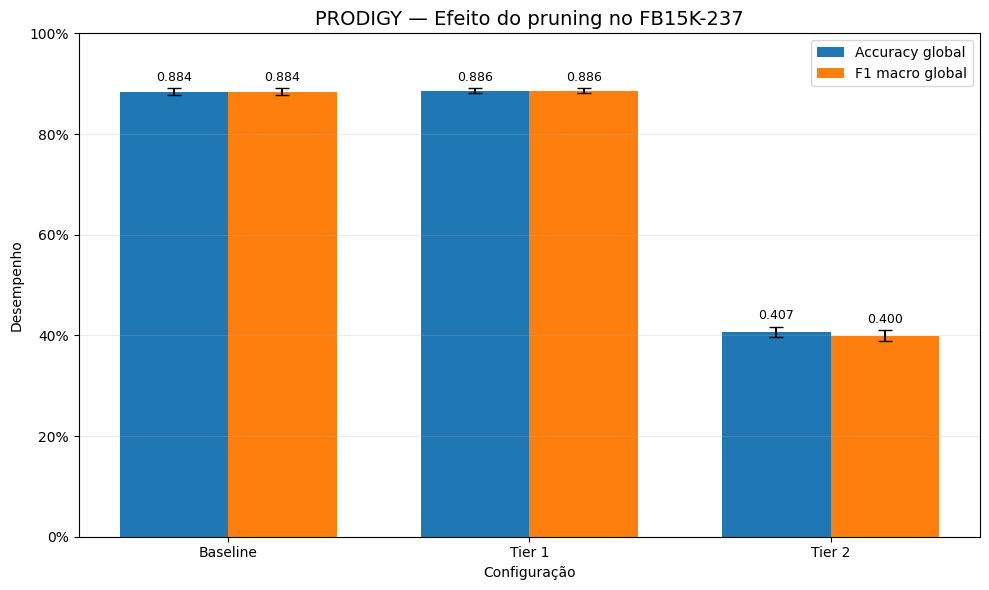

In [22]:
from matplotlib.ticker import PercentFormatter

plot_df = summary_df.set_index("Configuração").loc[
    ["Baseline", "Tier 1", "Tier 2"]
]

labels = plot_df.index.tolist()
x = np.arange(len(labels))
bar_width = 0.36

fig, ax = plt.subplots(figsize=(10, 6))

accuracy_means = plot_df["Accuracy média"].to_numpy()
accuracy_stds = plot_df["Accuracy desvio padrão"].to_numpy()

f1_means = plot_df["F1 macro médio"].to_numpy()
f1_stds = plot_df["F1 macro desvio padrão"].to_numpy()

bars_acc = ax.bar(
    x - bar_width / 2,
    accuracy_means,
    bar_width,
    yerr=accuracy_stds,
    capsize=5,
    label="Accuracy global",
)

bars_f1 = ax.bar(
    x + bar_width / 2,
    f1_means,
    bar_width,
    yerr=f1_stds,
    capsize=5,
    label="F1 macro global",
)

ax.set_title(
    "PRODIGY — Efeito do pruning no FB15K-237",
    fontsize=14,
)

ax.set_ylabel("Desempenho")
ax.set_xlabel("Configuração")
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_ylim(0, 1.0)
ax.legend()
ax.grid(axis="y", alpha=0.25)

# Valores médios acima das barras.
ax.bar_label(
    bars_acc,
    fmt="%.3f",
    padding=3,
    fontsize=9,
)

ax.bar_label(
    bars_f1,
    fmt="%.3f",
    padding=3,
    fontsize=9,
)

fig.tight_layout()

fig.savefig(
    "prodigy_pruning_comparison_fb15k237.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()